# Establish how many students and employees are impacted by each water filling station

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

# Change the path
df_density_map = pd.read_csv(r'D:\study\506\updated_densitymap_hourly_cleaned.csv')
df_bottle_fillers = pd.read_csv(r'D:\study\506\Bottle Fillers Inventory - ongoing.csv')
df_bottle_fillers_head = df_bottle_fillers.head()
df_density_map_head = df_density_map.head()
df_bottle_fillers_head, df_density_map_head

(  Address A          Address B    Floor   \
 0       100         Ashford St     First   
 1       120         Ashford St     First   
 2       120         Ashford St    Second   
 3         8  St. Mary's Street  Basement   
 4         8  St. Mary's Street     First   
 
                                          Description Accessibility  \
 0  Hallway across from vending machines, across f...        Public   
 1                             Kitchenette, Room 116A    Restricted   
 2                              Kitchenette, Room 222    Restricted   
 3                               Hallway by bathrooms           NaN   
 4                         Hallway by electrical room           NaN   
 
   Handicap Accessible Space@Bu room  Quantity Date Installed  \
 0                 Yes           191       1.0            NaN   
 1                 Yes          116A       1.0            NaN   
 2                 Yes           222       1.0            NaN   
 3                 NaN           B81    

Normalize and match addresses in updated_densitymap_hourly_cleaned.csv and Bottle Fillers Inventory - ongoing.csv. Print the Normalized address of Bottle Fillers Inventory - ongoing.csv.

In [4]:
from thefuzz import process  

# write the normalize_address function
def normalize_address(address):
    if pd.isnull(address):
        return None
    address = address.upper().strip()  
    suffixes = {'STREET': 'ST', 'AVENUE': 'AVE', 'BOULEVARD': 'BLVD', 'ROAD': 'RD', 'DRIVE': 'DR'}
    for long, short in suffixes.items():
        address = address.replace(long, short)
    # Remove all non-alphanumeric characters (except spaces and periods)
    address = ''.join(char for char in address if char.isalnum() or char in ' .')
    return address

# Define manual matching rules
manual_matches = {
    '8 ST MARYS ST': '8 ST. MARY\'S ST',
    '156 BAY STATE RD': '156 BAY STATE RD',
    
    #-------------Unmatched addresses-----------------
    '264 BAY STATE RD': '264-270 BAY STATE RD',
    '270 BAY STATE RD': '264-270 BAY STATE RD',
    '517 BEACON ST': '517-521 BEACON ST',
    '621 COMMONWEALTH AVE': '617-621 COMMONWEALTH AVE',
    '675 COMMONWEALTH AVE': '675 - 725 COMMONWEALTH AVE',
    '685 COMMONWEALTH AVE': '675 - 725 COMMONWEALTH AVE',
    '705 COMMONWEALTH AVE': '675 - 725 COMMONWEALTH AVE',
    '725 COMMONWEALTH AVE': '675 - 725 COMMONWEALTH AVE',
    '745 COMMONWEALTH AVE': '745 - 755 COMMONWEALTH AVE',
    '5 CUMMINGTON MALL': '3 - 5 CUMMINGTON MALL',
    '36 CUMMINGTON MALL': '30-38 CUMMINGTON MALL',
    '48 CUMMINGTON MALL': '48-52 CUMMINGTON MALL',
    '64 CUMMINGTON MALL': '64-86 CUMMINGTON MALL',
    '68 CUMMINGTON MALL': '64-86 CUMMINGTON MALL',
    '96 CUMMINGTON MALL': '96-100 CUMMINGTON MALL',
}

# Apply manual matching rules
def apply_manual_matches(address):
    return manual_matches.get(address, address)


def fuzzy_match(address, choices, score_cutoff=90):
    match = process.extractOne(address, choices, score_cutoff=score_cutoff)
    return match[0] if match else address

# Apply normalization to address columns
df_bottle_fillers['Normalized Address A'] = df_bottle_fillers['Address A'].astype(str).apply(normalize_address)
df_bottle_fillers['Normalized Address B'] = df_bottle_fillers['Address B'].astype(str).apply(normalize_address)
df_density_map['Normalized building_desc'] = df_density_map['building_desc'].astype(str).apply(normalize_address)

# Apply manual matching rules
df_bottle_fillers['Manual Matched Address A'] = df_bottle_fillers['Normalized Address A'].apply(apply_manual_matches)
df_bottle_fillers['Manual Matched Address B'] = df_bottle_fillers['Normalized Address B'].apply(apply_manual_matches)

# Apply fuzzy matching
#df_bottle_fillers['Fuzzy Matched Address A'] = df_bottle_fillers['Manual Matched Address A'].apply(lambda x: fuzzy_match(x, df_density_map['Normalized building_desc'].unique()))
#df_bottle_fillers['Fuzzy Matched Address B'] = df_bottle_fillers['Manual Matched Address B'].apply(lambda x: fuzzy_match(x, df_density_map['Normalized building_desc'].unique()))

df_bottle_fillers['Full Manual Matched Address'] = df_bottle_fillers['Manual Matched Address A'] + ' ' + df_bottle_fillers['Manual Matched Address B'].fillna('')

normalized_building_desc_set = set(df_density_map['Normalized building_desc'])

df_bottle_fillers['Is Matched'] = df_bottle_fillers['Full Manual Matched Address'].apply(lambda x: x in normalized_building_desc_set)

matched_addresses_in_bottle_fillers = df_bottle_fillers[df_bottle_fillers['Is Matched']]
print(matched_addresses_in_bottle_fillers[['Address A', 'Address B', 'Full Manual Matched Address']])

#print(df_bottle_fillers[['Address A', 'Normalized Address A', 'Manual Matched Address A']].head())
#print(df_density_map[['building_desc', 'Normalized building_desc']].head())


    Address A          Address B Full Manual Matched Address
0         100         Ashford St              100 ASHFORD ST
1         120         Ashford St              120 ASHFORD ST
2         120         Ashford St              120 ASHFORD ST
3           8  St. Mary's Street              8 ST. MARYS ST
4           8  St. Mary's Street              8 ST. MARYS ST
..        ...                ...                         ...
202   110-112    Cummington Mall      110112 CUMMINGTON MALL
203        33  Harry Agganis Way        33 HARRY AGGANIS WAY
204        33  Harry Agganis Way        33 HARRY AGGANIS WAY
205         1      University Rd             1 UNIVERSITY RD
206         1      University Rd             1 UNIVERSITY RD

[173 rows x 3 columns]


Print the successfully matched addresses in the two tables.

In [5]:
matched_df = pd.merge(
    df_bottle_fillers,
    df_density_map,
    left_on='Full Manual Matched Address',
    right_on='Normalized building_desc',
    how='inner'  
)

print(matched_df[['Full Manual Matched Address', 'building_desc']])

         Full Manual Matched Address         building_desc
0                     100 ASHFORD ST    100 ASHFORD STREET
1                     100 ASHFORD ST    100 ASHFORD STREET
2                     100 ASHFORD ST    100 ASHFORD STREET
3                     100 ASHFORD ST    100 ASHFORD STREET
4                     100 ASHFORD ST    100 ASHFORD STREET
...                              ...                   ...
17633483        33 HARRY AGGANIS WAY  33 HARRY AGGANIS WAY
17633484        33 HARRY AGGANIS WAY  33 HARRY AGGANIS WAY
17633485        33 HARRY AGGANIS WAY  33 HARRY AGGANIS WAY
17633486        33 HARRY AGGANIS WAY  33 HARRY AGGANIS WAY
17633487        33 HARRY AGGANIS WAY  33 HARRY AGGANIS WAY

[17633488 rows x 2 columns]


Display unmatched addresses in Bottle Fillers Inventory - ongoing.csv.

In [6]:
# Create a set of all normalized building descriptions from the density map for checking matches
normalized_building_desc_set = set(df_density_map['Normalized building_desc'])

# Filter out and display unmatched addresses
unmatched_addresses_in_bottle_fillers = df_bottle_fillers[~df_bottle_fillers['Is Matched']]
unmatched_addresses = unmatched_addresses_in_bottle_fillers[['Address A', 'Address B', 'Full Manual Matched Address']]

unmatched_addresses

,Address A,Address B,Full Manual Matched Address
33,264,Bay State Road,264 BAY STATE RD
34,264,Bay State Road,264 BAY STATE RD
35,264,Bay State Road,264 BAY STATE RD
36,270,Bay State Road,270 BAY STATE RD
38,517,Beacon St,517 BEACON ST
67,621,Commonwealth Ave,621 COMMONWEALTH AVE
68,621,Commonwealth Ave,621 COMMONWEALTH AVE
77,675,Commonwealth Ave,675 COMMONWEALTH AVE
78,675,Commonwealth Ave,675 COMMONWEALTH AVE
79,675,Commonwealth Ave,675 COMMONWEALTH AVE


Calculate the sum of daily foot traffic for each location. If a location has multiple water stations, divide the sum of foot traffic by the number of water stations.

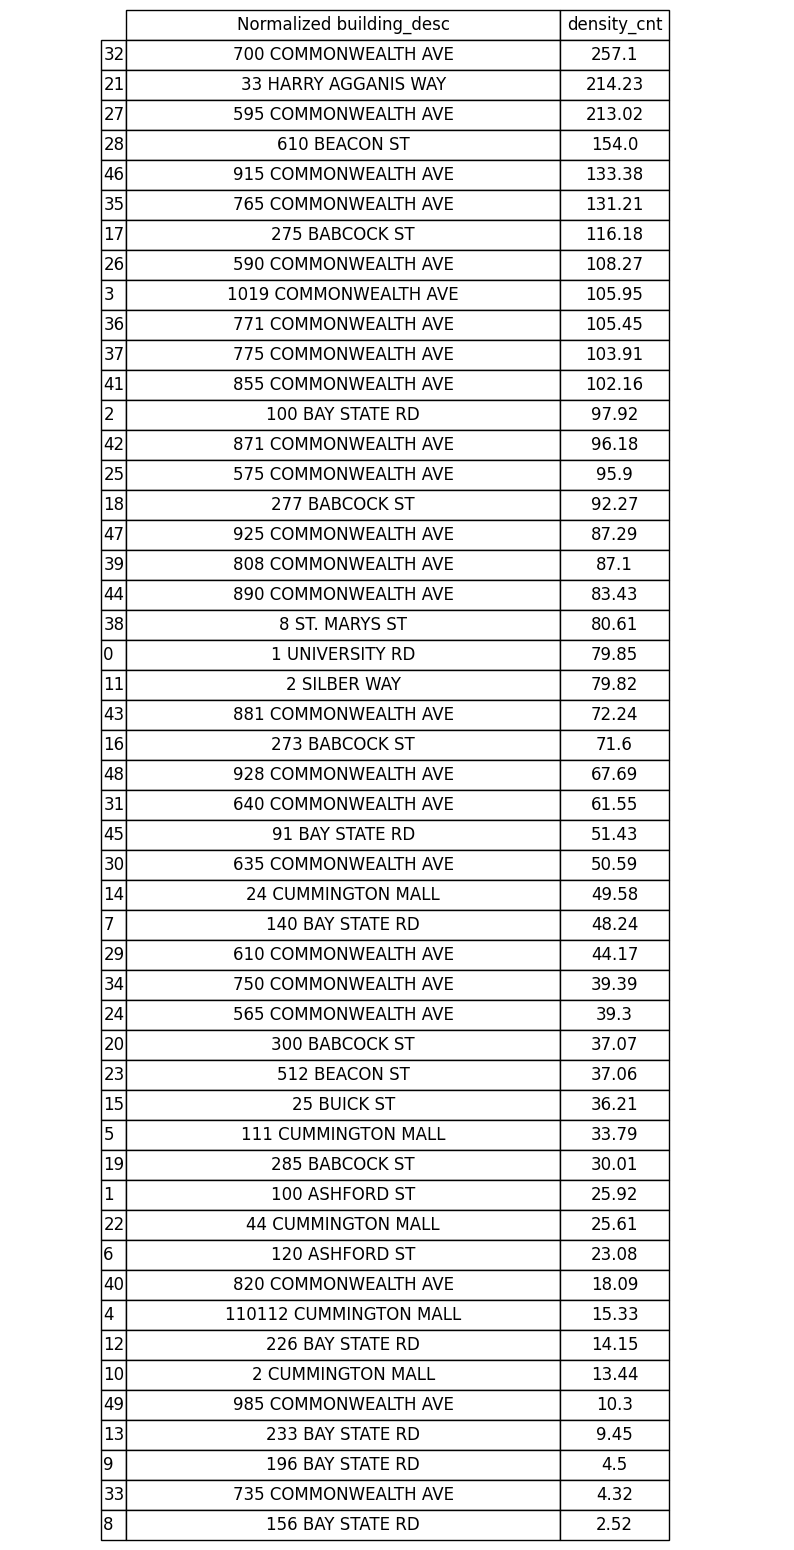

In [22]:
import matplotlib.pyplot as plt
from pandas.plotting import table

# Calculate the sum of 'density_cnt' for each address, each day, and each hour
df_density_map_grouped = df_density_map.groupby(['Normalized building_desc', 'date', 'hour'])['density_cnt'].sum().reset_index()

# Calculate the overall average 'density_cnt' for each address
average_density_per_address = df_density_map_grouped.groupby('Normalized building_desc')['density_cnt'].mean().reset_index()

# Count how many times each 'Full Manual Matched Address' appears
address_counts = df_bottle_fillers['Full Manual Matched Address'].value_counts().reset_index()
address_counts.columns = ['Full Manual Matched Address', 'Count']

average_density_adjusted = pd.merge(average_density_per_address, address_counts, left_on='Normalized building_desc', right_on='Full Manual Matched Address')

average_density_adjusted[['Normalized building_desc', 'density_cnt']]

# Now, sort the results in descending order by the 'Adjusted Average Density':
average_density_adjusted_sorted = average_density_adjusted.sort_values(by='density_cnt', ascending=False)

average_density_adjusted_sorted['density_cnt'] = average_density_adjusted_sorted['density_cnt'].round(2)

#average_density_adjusted_sorted.to_csv('results.csv', index=False)

# Display the sorted adjusted average density values along with the normalized building description
average_density_adjusted_sorted[['Normalized building_desc', 'density_cnt']]

df_display = average_density_adjusted_sorted[['Normalized building_desc', 'density_cnt']]

fig, ax = plt.subplots(figsize=(10, len(df_display)*0.3))  
ax.axis('off')

tbl = table(ax, df_display, loc='center', cellLoc='center', colWidths=[0.4,0.1])
tbl.auto_set_font_size(False)
tbl.set_fontsize(12)  
tbl.scale(1.4, 1.8)  

plt.savefig('table_display.png', bbox_inches='tight', dpi=200)